# Data: Acquiring, Cleaning and Reshaping

## *Workshop 2*  [![Open In Colab](https://github.com/oballinger/BASC0005/blob/main/colab-badge.png?raw=1)](https://colab.research.google.com/github/christy040406-maker/QM2/blob/main/notebooks/W02.%20Pandas.ipynb)

This week's lecture made three points: **dirty data can do real damage**, there are **three ways to get data** (download, API, scrape), and **data types and data structure** (long vs wide, tidy data) decide what you can do with a dataset. This workshop practises each of them with *pandas*, in the same order.

### Aims

- Diagnose a real, consequential spreadsheet error (Reinhart & Rogoff, 2010)
- Get data three ways: download a CSV, call an API (World Bank), scrape an HTML table
- Inspect `dtypes` and fix the usual problems: numbers stored as text, dates as strings, categories
- Select rows and columns with `.loc[]` and boolean filters
- Reshape panel data between **wide** and **long** with `melt()` and `pivot()`, using Global Fishing Watch data
- Get into the habit of asking "is this result real, or is it an artefact of the data?"

The core path should take about two hours. Sections marked **(Optional)** are extensions.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 20)

## 1. Dirty data kills: Reinhart & Rogoff

In 2010 Carmen Reinhart and Kenneth Rogoff published *Growth in a Time of Debt*. Its headline: countries with public debt above 90% of GDP had average real growth of about **−0.1%**. Politicians used it to justify austerity. In 2013 Thomas Herndon, a graduate student, tried to replicate it from the authors' own spreadsheet and got **+2.2%** instead ([Herndon, Ash & Pollin, 2013](https://doi.org/10.1093/cje/bet075)).

Below is the replication dataset: one row per **country-year**, with debt/GDP (%) and real GDP growth (%), for 20 advanced economies from 1946 to 2009.

In [30]:
rr = pd.read_csv("https://storage.googleapis.com/qm2/2627/w02/reinhart_rogoff.csv")
print(rr.shape)
rr.head()

(1175, 4)


,Country,Year,debtgdp,dRGDP
0,Australia,1946,190.42,-3.558
1,Australia,1947,177.32,2.459
2,Australia,1948,148.93,6.438
3,Australia,1949,125.83,6.612
4,Australia,1950,109.81,6.920


Reinhart and Rogoff grouped country-years into four debt "buckets". `pd.cut` does this: it turns a continuous number into an ordered **categorical** variable (we come back to categories in section 3).

In [31]:
buckets = [0, 30, 60, 90, np.inf]
labels = ["0-30%", "30-60%", "60-90%", "90%+"]
rr["debt_bucket"] = pd.cut(rr["debtgdp"], bins=buckets, labels=labels, right=False)

rr["debt_bucket"].value_counts().sort_index()

,count
debt_bucket,
0-30%,426
30-60%,439
60-90%,200
90%+,110


### The "published" analysis

Here is an analysis that reproduces the steps behind the 2010 headline figure. Read it carefully and run it.

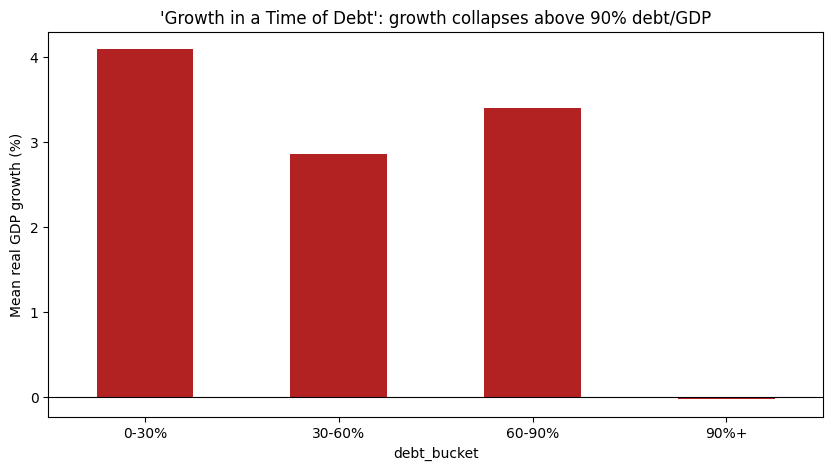

,dRGDP
debt_bucket,
0-30%,4.09
30-60%,2.85
60-90%,3.40
90%+,-0.02


In [32]:
countries = sorted(rr["Country"].unique())
sample = rr[rr["Country"].isin(countries[5:])]

early_years = (((sample["Country"] == "New Zealand") & (sample["Year"] < 1950)) |
               ((sample["Country"] == "Australia") & (sample["Year"] < 1951)) |
               ((sample["Country"] == "Canada") & (sample["Year"] < 1951)))
sample = sample[~early_years]

country_means = sample.groupby(["debt_bucket", "Country"], observed=True)["dRGDP"].mean()
published = country_means.groupby("debt_bucket", observed=True).mean()

published.plot(kind="bar", color="firebrick")
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("Mean real GDP growth (%)")
plt.title("'Growth in a Time of Debt': growth collapses above 90% debt/GDP")
plt.xticks(rotation=0)
plt.show()
published.round(2)

Now the simplest possible analysis: take **every** country-year in the data and average growth within each bucket.

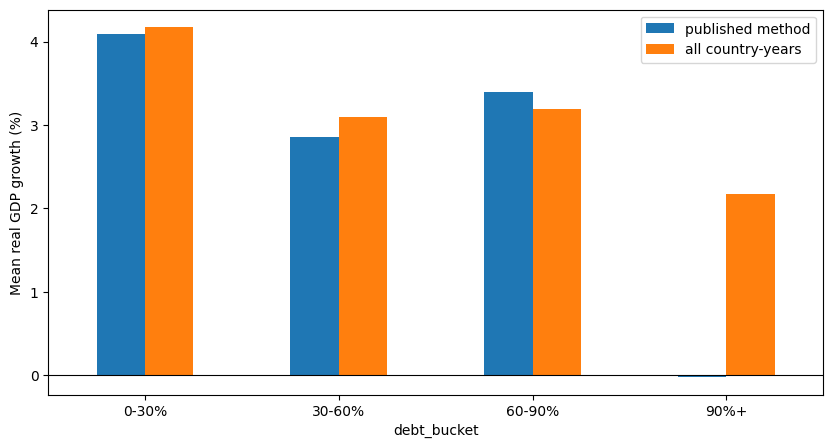

,published method,all country-years
debt_bucket,,
0-30%,4.09,4.17
30-60%,2.85,3.09
60-90%,3.40,3.19
90%+,-0.02,2.17


In [33]:
simple = rr.groupby("debt_bucket", observed=True)["dRGDP"].mean()

compare = pd.DataFrame({"published method": published, "all country-years": simple})
compare.plot(kind="bar")
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("Mean real GDP growth (%)")
plt.xticks(rotation=0)
plt.show()
compare.round(2)

### Exercise: spot the spreadsheet error

The two methods agree for the first three buckets but disagree dramatically above 90%. The "published" cell makes **three** choices that the simple average does not.

1. Identify all three. (Hint: read the published cell line by line. What does `countries[5:]` keep? Which country-years does `early_years` remove? How many country-years does each country contribute to the 90%+ bucket, and how much weight does each country get in the final average?)
2. Undo them **one at a time** and record the 90%+ number after each change. Which choice matters most?
3. Look at the 90%+ bucket country by country (`sample[sample["debt_bucket"] == "90%+"].groupby("Country")["dRGDP"].agg(["mean", "count"])`). One country has a single observation. What does that one year do to an average where every country counts equally?

Only one of the three choices was an accident (the Excel formula did not reach the first five rows). The other two were methodological decisions. Are they defensible?

In [34]:
# 计算“每个国家权重相同”的平均值
def equal_country_mean(df):
    country_means = df.groupby(
        ["debt_bucket", "Country"], observed=True
    )["dRGDP"].mean()

    return country_means.groupby(
        "debt_bucket", observed=True
    ).mean()


countries = sorted(rr["Country"].unique())

# Choice 1: countries[5:] 丢掉了哪些国家？
print("Omitted countries:", countries[:5])

original_sample = rr[
    rr["Country"].isin(countries[5:])
].copy()


# Choice 2: 哪些早期年份被删除？
def early_year_mask(df):
    return (
        ((df["Country"] == "New Zealand") & (df["Year"] < 1950)) |
        ((df["Country"] == "Australia") & (df["Year"] < 1951)) |
        ((df["Country"] == "Canada") & (df["Year"] < 1951))
    )


print("Early observations removed:")
display(
    rr.loc[
        early_year_mask(rr),
        ["Country", "Year", "debtgdp", "dRGDP"]
    ]
)

published_sample = original_sample.loc[
    ~early_year_mask(original_sample)
].copy()


# Choice 3: 查看 90%+ 组中，每个国家的平均值和观察数量
country_stats = (
    published_sample[
        published_sample["debt_bucket"] == "90%+"
    ]
    .groupby("Country")["dRGDP"]
    .agg(["mean", "count"])
)

display(country_stats)


# 原始 published calculation
published_90 = equal_country_mean(
    published_sample
).loc["90%+"]


# Undo choice 1：恢复前五个国家，但保留其他两个选择
all_countries_after_early_filter = rr.loc[
    ~early_year_mask(rr)
].copy()

undo_omission = equal_country_mean(
    all_countries_after_early_filter
).loc["90%+"]


# Undo choice 2：恢复被删除的早期年份
undo_early_years = equal_country_mean(
    original_sample
).loc["90%+"]


# Undo choice 3：每个 country-year 权重相同
undo_equal_country_weight = published_sample.loc[
    published_sample["debt_bucket"] == "90%+",
    "dRGDP"
].mean()


# Undo all three，作为参考
undo_all = rr.loc[
    rr["debt_bucket"] == "90%+",
    "dRGDP"
].mean()


results = pd.Series({
    "Published calculation": published_90,
    "Undo omitted countries": undo_omission,
    "Undo early-year exclusions": undo_early_years,
    "Undo equal-country weighting": undo_equal_country_weight,
    "Undo all three": undo_all
})

display(results.round(2))

Omitted countries: ['Australia', 'Austria', 'Belgium', 'Canada', 'Denmark']
Early observations removed:


,Country,Year,debtgdp,dRGDP
0,Australia,1946,190.42,-3.558
1,Australia,1947,177.32,2.459
2,Australia,1948,148.93,6.438
3,Australia,1949,125.83,6.612
4,Australia,1950,109.81,6.920
189,Canada,1946,135.91,-1.026
190,Canada,1947,117.03,4.426
191,Canada,1948,105.18,1.833
192,Canada,1949,124.02,2.175
193,Canada,1950,110.97,7.376


,mean,count
Country,,
Greece,2.910632,19
Ireland,2.428571,7
Italy,1.028900,10
Japan,0.687182,11
New Zealand,-7.635000,1
UK,2.399053,19
US,-1.988750,4


,0
Published calculation,-0.02
Undo omitted countries,0.30
Undo early-year exclusions,1.43
Undo equal-country weighting,1.69
Undo all three,2.17


**Interpretation.** Even with the corrected numbers, high-debt country-years grow more slowly (about 2.2% vs 3-4%). Does that mean debt *causes* slow growth? Write two sentences on why the causation could run the other way.

## 2. Data acquisition

The lecture listed three ways to get data from the internet:

| Method | What you get | Example below |
|---|---|---|
| **Download** | a packaged file (CSV, Excel...) | UK incomes by percentile (IFS) |
| **API** | structured data (usually JSON) returned by a server in response to a URL | World Bank GDP |
| **Web scraping** | whatever is displayed on a web page | Netflix Top 10 |

### 2.1 Download: UK incomes by percentile

This file comes from the Institute for Fiscal Studies ([where do you fit in?](https://ifs.org.uk/tools_and_resources/where_do_you_fit_in)), based on the Family Resources Survey 2010-11. Each row is a percentile of the income distribution, and incomes are **equivalised**: adjusted for household size, because a couple needs more than a single person but not twice as much ([equivalisation](https://en.wikipedia.org/wiki/Equivalisation)).

`read_csv` can read straight from a URL, so you do not need to download anything by hand. We use the first column (the percentile) as the index.

In [35]:
income = pd.read_csv("https://s3.eu-west-2.amazonaws.com/qm2/wk2/incomes.csv", index_col=0)
income.head()

,"Net equivalised household income in 2010-11, week","Childless couple, annual income","Couple, two children under 14","Couple, three children under 14",Couple with one child under 14,Couple with two children aged 15 to 18,"Couple, two children under 14 plus dependent adult",Single adult,"Lone parent, one child under 14","Lone parent, two children under 14","Lone parent, two children aged 15-18",ANNOTATIONS,1979 to 1996-97,1996-97 to 2009-10,1996-97 to 2010-11
Percentile Point,,,,,,,,,,,,,,,
1,33.50,"1,746.92","2,445.69","2,795.08","2,096.31","2,899.89","3,022.18","1,170.44","1,519.82","1,869.21","2,323.41",NaN,NaN,NaN,NaN
2,98.60,"5,141.01","7,197.41","8,225.61","6,169.21","8,534.07","8,893.95","3,444.48","4,472.68","5,500.88","6,837.54",NaN,-0.20%,-1.30%,-0.50%
3,128.56,"6,703.11","9,384.36","10,724.98","8,043.74","11,127.17","11,596.39","4,491.09","5,831.71","7,172.33","8,915.14",NaN,0.40%,0.10%,0.10%
4,151.05,"7,875.75","11,026.05","12,601.20","9,450.90","13,073.75","13,625.05","5,276.75","6,851.90","8,427.05","10,474.75",NaN,0.50%,0.80%,0.60%
5,166.32,"8,671.91","12,140.68","13,875.06","10,406.30","14,395.38","15,002.41","5,810.18","7,544.57","9,278.95","11,533.65",NaN,0.70%,1.00%,0.90%


The last row is the top percentile, "the 1%":

In [36]:
income.tail()

,"Net equivalised household income in 2010-11, week","Childless couple, annual income","Couple, two children under 14","Couple, three children under 14",Couple with one child under 14,Couple with two children aged 15 to 18,"Couple, two children under 14 plus dependent adult",Single adult,"Lone parent, one child under 14","Lone parent, two children under 14","Lone parent, two children aged 15-18",ANNOTATIONS,1979 to 1996-97,1996-97 to 2009-10,1996-97 to 2010-11
Percentile Point,,,,,,,,,,,,,,,
95,1075.73,"56,088.56","78,523.99","89,741.70","67,306.27","93,107.01","97,033.21","37,579.34","48,797.05","60,014.76","74,597.79",NaN,2.90%,2.00%,1.30%
96,1174.48,"61,237.18","85,732.05","97,979.49","73,484.61","101,653.72","105,940.32","41,028.91","53,276.35","65,523.78","81,445.45",NaN,3.00%,2.00%,1.40%
97,1302.74,"67,925.07","95,095.10","108,680.12","81,510.09","112,755.62","117,510.37","45,509.80","59,094.81","72,679.83","90,340.35",NaN,3.20%,2.20%,1.60%
98,1523.31,"79,425.23","111,195.32","127,080.36","95,310.27","131,845.88","137,405.64","53,214.90","69,099.95","84,984.99","105,635.55",NaN,3.20%,2.70%,1.70%
99,2090.35,"108,990.74","152,587.04","174,385.19","130,788.89","180,924.64","188,553.99","73,023.80","94,821.95","116,620.10","144,957.69",NaN,NaN,NaN,NaN


#### Selecting rows, columns and cells

- a **row** by its index label: `income.loc[90]`
- a range of rows: `income.loc[90:95]` (with `.loc`, the end point is *included*)
- a **column** by name: `income["Single adult"]`
- a single **cell**: `income.loc[90, "Single adult"]`

`.iloc[]` does the same by *position* (0, 1, 2, ...) rather than by label.

In [37]:
weekly = "Net equivalised household income in 2010-11, week"
income.loc[90:95, weekly]

,"Net equivalised household income in 2010-11, week"
Percentile Point,
90,845.54
91,876.63
92,911.29
93,957.14
94,1016.37
95,1075.73


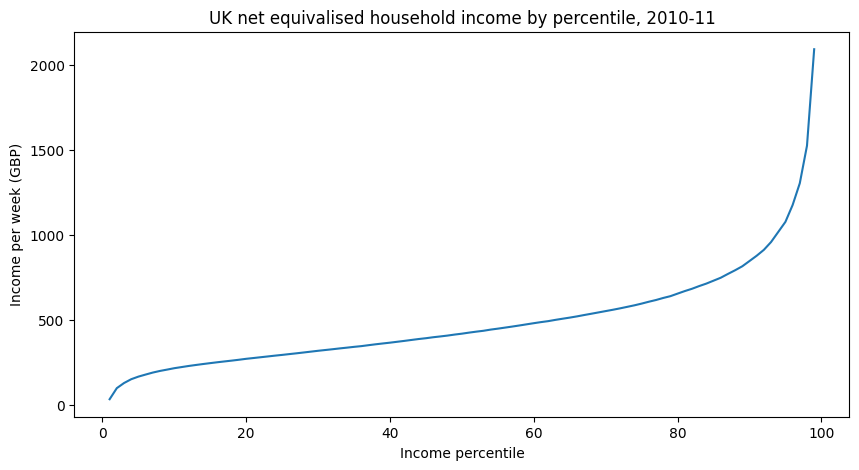

In [38]:
income[weekly].plot()
plt.title("UK net equivalised household income by percentile, 2010-11")
plt.xlabel("Income percentile")
plt.ylabel("Income per week (GBP)")
plt.show()

Linear through the middle, then a steep rise at the top.

### Exercise: mean vs median

Add horizontal lines (`plt.axhline`) for the **mean** and the **median** of the weekly income column to the plot above. Which is higher, and why? What does the median mean in this context?

(Careful: the mean of 99 percentile points is not the mean household income. Why not?)

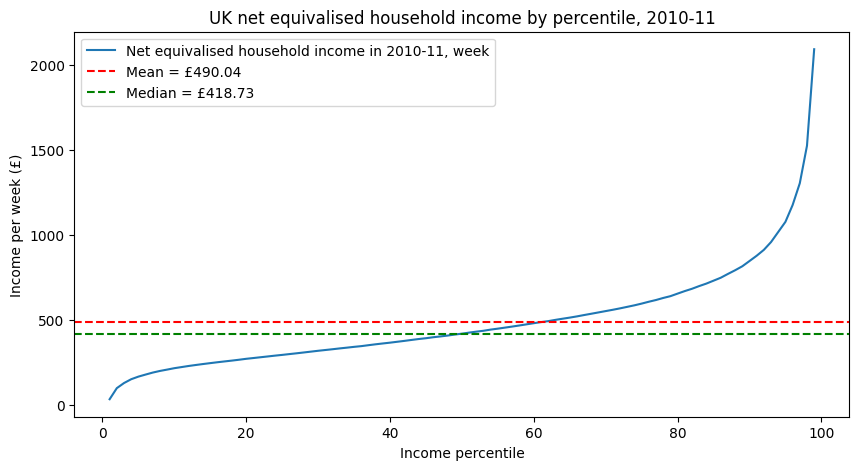

Mean: 490.0385858585858
Median: 418.73


In [39]:
mean_income = income[weekly].mean()
median_income = income[weekly].median()

income[weekly].plot()

plt.axhline(
    mean_income,
    color="red",
    linestyle="--",
    label=f"Mean = £{mean_income:.2f}"
)

plt.axhline(
    median_income,
    color="green",
    linestyle="--",
    label=f"Median = £{median_income:.2f}"
)

plt.title("UK net equivalised household income by percentile, 2010-11")
plt.xlabel("Income percentile")
plt.ylabel("Income per week (£)")
plt.legend()
plt.show()

print("Mean:", mean_income)
print("Median:", median_income)

### 2.2 API: the World Bank

An API is a URL that returns data instead of a web page. As in the lecture's Google Maps example, the URL has a **base** and some **parameters**. The World Bank's API needs no key:

`https://api.worldbank.org/v2/country/AGO;BRA;COL/indicator/NY.GDP.MKTP.CD?format=json&date=2000:2024&per_page=1000`

- `country/AGO;BRA;COL`: Angola, Brazil, Colombia (ISO3 codes, separated by `;`)
- `indicator/NY.GDP.MKTP.CD`: GDP in current US$ (search for indicator codes at [data.worldbank.org](https://data.worldbank.org))
- `format=json`, `date=2000:2024`, `per_page=1000`: return JSON, for these years, all on one page

Paste the URL into your browser to see the raw response first. `requests` lets us pass the parameters as a dictionary:

In [40]:
url = "https://api.worldbank.org/v2/country/AGO;BRA;COL/indicator/NY.GDP.MKTP.CD"
params = {"format": "json", "date": "2000:2024", "per_page": 1000}
response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
print(response.status_code)
meta, records = response.json()
print("Data downloaded:", pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC"))
meta
url = "https://api.worldbank.org/v2/country/AGO;BRA;COL/indicator/NY.GDP.MKTP.CD"
params = {"format": "json", "date": "2000:2024", "per_page": 1000}
response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
print(response.status_code)
meta, records = response.json()
print("Data downloaded:", pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC"))
metaurl = "https://api.worldbank.org/v2/country/AGO;BRA;COL/indicator/NY.GDP.MKTP.CD"
params = {"format": "json", "date": "2000:2024", "per_page": 1000}

response = requests.get(url, params=params, timeout=30)
print(response.status_code)   # 200 = OK
meta, records = response.json()
meta

200
Data downloaded: 2026-10-17 19:58 UTC
200
Data downloaded: 2026-10-17 19:58 UTC
200


{'page': 1,
 'pages': 1,
 'per_page': 1000,
 'total': 75,
 'sourceid': '2',
 'lastupdated': '2026-10-08'}

The response is **JSON**: a list containing a metadata dictionary and a list of records. Each record is a dictionary, and some values are dictionaries themselves (**nested**):

In [41]:
records[0]

{'indicator': {'id': 'NY.GDP.MKTP.CD', 'value': 'GDP (current US$)'},
 'country': {'id': 'AO', 'value': 'Angola'},
 'countryiso3code': 'AGO',
 'date': '2024',
 'value': 103080538044.058,
 'unit': '',
 'obs_status': '',
 'decimal': 0}

`pd.json_normalize` flattens nested JSON into a table: `country: {"value": "Angola"}` becomes a column called `country.value`.

In [42]:
gdp = pd.json_normalize(records)
gdp = gdp[["country.value", "countryiso3code", "date", "value"]]
gdp.columns = ["country", "iso3", "year", "gdp_usd"]
gdp.head()

,country,iso3,year,gdp_usd
0,Angola,AGO,2024,1.030805e+11
1,Angola,AGO,2023,1.060423e+11
2,Angola,AGO,2022,1.282340e+11
3,Angola,AGO,2021,7.828392e+10
4,Angola,AGO,2020,5.851203e+10


Before plotting, **check the dtypes**. Is `year` a number?

In [43]:
gdp.dtypes

,0
country,object
iso3,object
year,object
gdp_usd,float64


`year` is stored as text (`object` in pandas 2, `str` in pandas 3), because JSON sent it as `"2024"` in quotes. Text sorts alphabetically and cannot go on a numeric axis, so convert it:

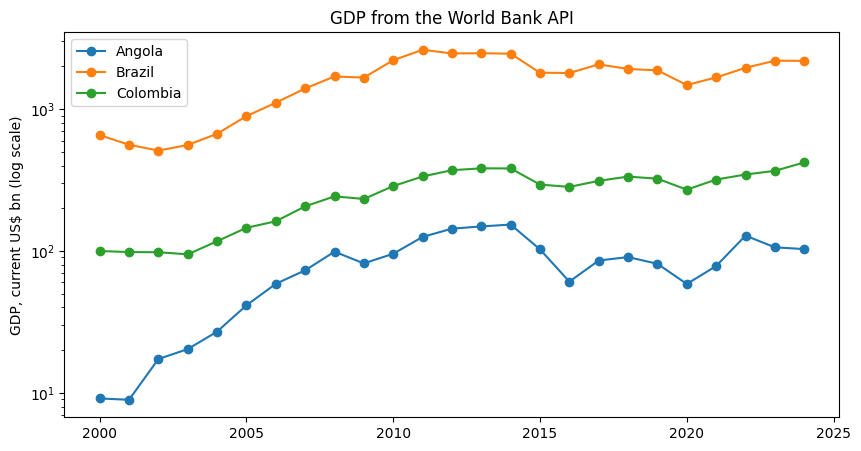

In [44]:
gdp["year"] = gdp["year"].astype(int)
gdp["gdp_bn"] = gdp["gdp_usd"] / 1e9

for country, group in gdp.groupby("country"):
    group = group.sort_values("year")
    plt.plot(group["year"], group["gdp_bn"], marker="o", label=country)
plt.yscale("log")
plt.ylabel("GDP, current US$ bn (log scale)")
plt.legend()
plt.title("GDP from the World Bank API")
plt.show()

### Exercise: another indicator

Use the same pattern to get a different indicator for the same three countries, for example total fisheries production in metric tons (`ER.FSH.PROD.MT`) or population (`SP.POP.TOTL`). Plot it. Do any years come back as `NaN` (missing)? Why might that be?

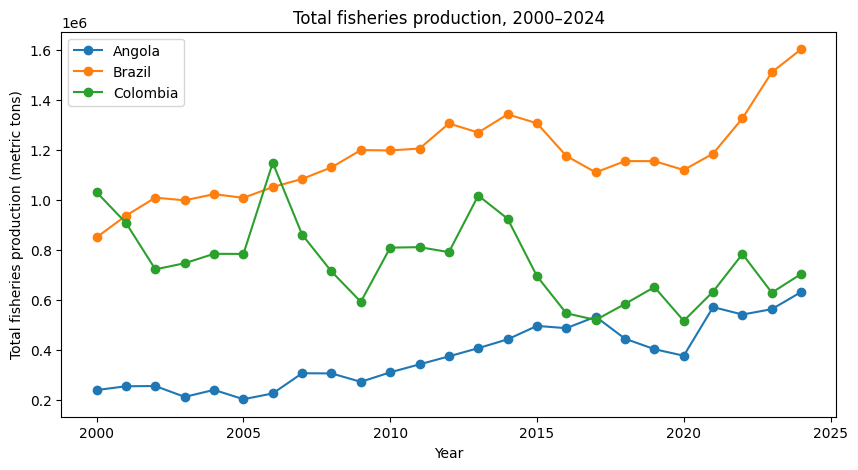

Missing observations:


,country,year


Number of missing years by country:


,fisheries_mt
country,
Angola,0
Brazil,0
Colombia,0


In [45]:
# Get total fisheries production data
url = "https://api.worldbank.org/v2/country/AGO;BRA;COL/indicator/ER.FSH.PROD.MT"

params = {
    "format": "json",
    "date": "2000:2024",
    "per_page": 1000
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

meta, records = response.json()

# Convert the JSON records into a DataFrame
fisheries = pd.json_normalize(records)

fisheries = fisheries[
    ["country.value", "countryiso3code", "date", "value"]
]

fisheries.columns = [
    "country", "iso3", "year", "fisheries_mt"
]

fisheries["year"] = fisheries["year"].astype(int)


# Plot one line for each country
for country, group in fisheries.groupby("country"):
    group = group.sort_values("year")

    plt.plot(
        group["year"],
        group["fisheries_mt"],
        marker="o",
        label=country
    )

plt.xlabel("Year")
plt.ylabel("Total fisheries production (metric tons)")
plt.title("Total fisheries production, 2000–2024")
plt.legend()
plt.show()


# Check for missing values
missing = fisheries[
    fisheries["fisheries_mt"].isna()
][["country", "year"]]

print("Missing observations:")
display(missing)

print("Number of missing years by country:")
display(
    fisheries.groupby("country")["fisheries_mt"]
    .apply(lambda x: x.isna().sum())
)

**Interpretation.** The lecture slide (made a few years ago) gave Angola's 2019 GDP as **69.3** US$ bn. What does the API say now?

In [46]:
gdp[gdp["year"].between(2019, 2021)].pivot(index="country", columns="year", values="gdp_bn").round(1)

year,2019,2020,2021
country,,,
Angola,81.2,58.5,78.3
Brazil,1873.3,1476.1,1670.6
Colombia,323.0,270.3,318.5


Same source, same country, same year, different number. Official statistics are **revised** as better information arrives, so a number is only meaningful alongside the date you downloaded it (its *vintage*). This is one reason to fetch data with code: you can re-run the script and see exactly what changed.

### 2.3 Web scraping: the Netflix Top 10

When there is no download or API, you can take data from the page itself. For HTML tables, `pd.read_html` does it in one line and returns a **list** of every table on the page. (The page changes every week, so your output will differ from the one saved here.)

In [47]:
import io

netflix_response = requests.get(
    "https://top10.netflix.com/",
    headers={"User-Agent": "BASC0005 student project"},
    timeout=30
)
netflix_response.raise_for_status()
tables = pd.read_html(io.StringIO(netflix_response.text))
print(len(tables), "table(s) found")
top10 = tables[0]
top10


1 table(s) found


,Ranking,Unnamed: 1,Views,Runtime,Hours Viewed
0,01Animals,1,23800000,1:48,42800000
1,02Doing Life,2,18200000,1:48,32800000
2,03Ice Age,1,11200000,1:23,15500000
3,04Ice Age: Collision Course,4,9300000,1:37,15100000
4,05Ice Age: Dawn of the Dinosaurs,4,8000000,1:35,12700000
5,06Ice Age: The Meltdown,1,7700000,1:33,11900000
6,07UNABOMBER,3,7300000,1:40,12100000
7,08The Widower: 'Til Death Do Us Part,2,7200000,1:32,11000000
8,09Ice Age: Continental Drift,1,6600000,1:31,10000000
9,10The Forever Purge,2,4000000,1:43,6900000


This is typical scraped data: it *looks* right on screen but is messy underneath.
- The rank and the title have been squashed into one column (`"01Why Did I..."`).
- One column has no name (`Unnamed: 1`; on the website it is the number of weeks in the Top 10).
- `Runtime` is text like `"1:51"`, not a duration.

Check with `.dtypes`, then fix it:

In [48]:
top10.dtypes

,0
Ranking,object
Unnamed: 1,int64
Views,int64
Runtime,object
Hours Viewed,int64


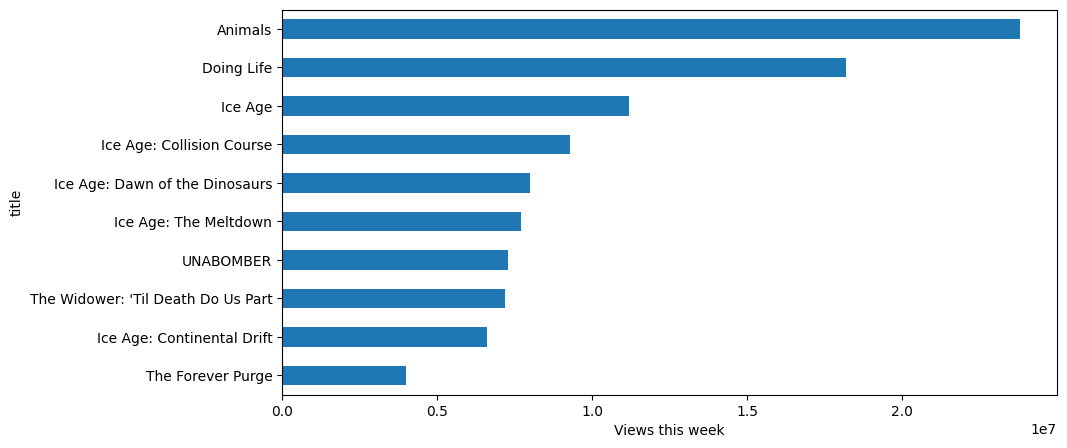

,title,Views,Hours Viewed,runtime_min,calculated_views,difference (%)
0,Animals,23800000,42800000,108.0,23777777.78,0.09
1,Doing Life,18200000,32800000,108.0,18222222.22,-0.12
2,Ice Age,11200000,15500000,83.0,11204819.28,-0.04
3,Ice Age: Collision Course,9300000,15100000,97.0,9340206.19,-0.43
4,Ice Age: Dawn of the Dinosaurs,8000000,12700000,95.0,8021052.63,-0.26
5,Ice Age: The Meltdown,7700000,11900000,93.0,7677419.35,0.29
6,UNABOMBER,7300000,12100000,100.0,7260000.00,0.55
7,The Widower: 'Til Death Do Us Part,7200000,11000000,92.0,7173913.04,0.36
8,Ice Age: Continental Drift,6600000,10000000,91.0,6593406.59,0.10
9,The Forever Purge,4000000,6900000,103.0,4019417.48,-0.48


Small differences are expected because the published figures are rounded.
For the same total hours viewed, a shorter runtime produces more Views.
Views are viewing equivalents, not a count of unique viewers.


In [49]:
top10 = top10.rename(columns={top10.columns[1]: "weeks_in_top10"})
top10["rank"] = top10["Ranking"].str[:2].astype(int)     # first two characters
top10["title"] = top10["Ranking"].str[2:]                 # everything after them
top10["runtime"] = pd.to_timedelta(top10["Runtime"] + ":00")   # "1:51" -> 1 h 51 min
top10["runtime_min"] = top10["runtime"].dt.total_seconds() / 60

top10 = top10[["rank", "title", "weeks_in_top10", "Views", "runtime_min", "Hours Viewed"]]
top10.plot.barh(x="title", y="Views", legend=False)
plt.gca().invert_yaxis()
plt.xlabel("Views this week")
plt.show()
top10

# Interpretation: check Netflix's definition of Views
views_check = top10[["title", "Views", "Hours Viewed", "runtime_min"]].copy()
views_check["calculated_views"] = (
    views_check["Hours Viewed"] / (views_check["runtime_min"] / 60)
)
views_check["difference (%)"] = (
    (views_check["Views"] - views_check["calculated_views"])
    / views_check["calculated_views"] * 100
)
display(views_check.round(2))
print("Small differences are expected because the published figures are rounded.")
print("For the same total hours viewed, a shorter runtime produces more Views.")
print("Views are viewing equivalents, not a count of unique viewers.")

**Interpretation.** Netflix defines "Views" as hours viewed divided by runtime. Check this with the columns you have. Which kind of title does this definition favour, long or short ones?

> **Scraping etiquette.** Scraping can break a site's terms of service; check them, and never hammer a site with requests. Some sites (Wikipedia included) refuse requests that do not identify themselves. If `read_html(url)` gives `HTTP Error 403: Forbidden`, fetch the page with `requests.get(url, headers={"User-Agent": "BASC0005 student project"})` and pass `io.StringIO(response.text)` to `read_html`.

### (Optional) Exercise: scrape a Wikipedia table

Scrape the ranking of countries by exclusive economic zone (EEZ) area from `https://en.wikipedia.org/wiki/Exclusive_economic_zone` (the table with columns `Rank`, `Country`, `EEZ (km2)`, `Shelf (km2)`). The page has about 20 tables: use `read_html(..., match="Shelf")` to select the right one, then tidy the column names (remove footnote markers like `[103]`) and check the dtypes. Make a bar chart of the 15 largest EEZs. Which country comes first, and why is that surprising? (Hint: what counts as one country's EEZ here?)

Original columns:
Index(['Rank', 'Country', 'EEZ (km2)[103]', 'Shelf (km2)[103]',
       'EEZ+TIA[note 5] (km2)[103]'],
      dtype='object')

Cleaned columns:
Index(['Rank', 'Country', 'EEZ (km2)', 'Shelf (km2)', 'EEZ+TIA (km2)'], dtype='object')

Data types:
Rank               int64
Country           object
EEZ (km2)        float64
Shelf (km2)      float64
EEZ+TIA (km2)    float64
dtype: object


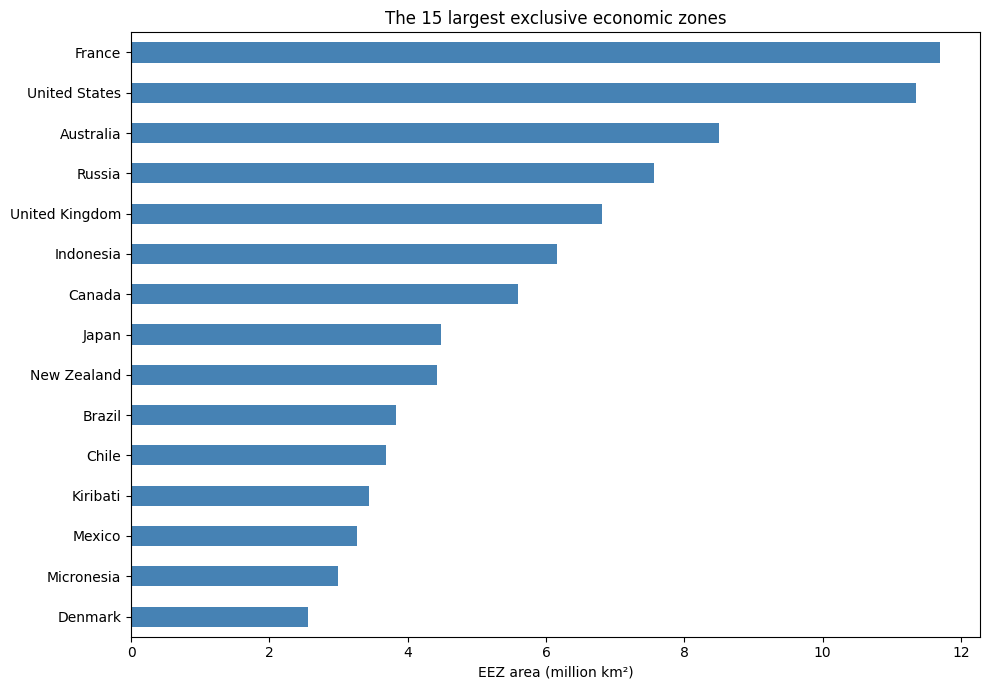

,Rank,Country,EEZ (km2)
0,1,France,11691000.0
1,2,United States,11351000.0
2,3,Australia,8505348.0
3,4,Russia,7566673.0
4,5,United Kingdom,6805586.0
5,6,Indonesia,6159032.0
6,7,Canada,5599077.0
7,8,Japan,4479388.0
8,9,New Zealand,4420565.0
9,10,Brazil,3830955.0


In [50]:
import io
import io

url = "https://en.wikipedia.org/wiki/Exclusive_economic_zone"

# Fetch the webpage
response = requests.get(
    url,
    headers={"User-Agent": "BASC0005 student project"},
    timeout=30
)
response.raise_for_status()

# Select the table containing "Shelf"
tables = pd.read_html(
    io.StringIO(response.text),
    match="Shelf"
)

eez = tables[0]

print("Original columns:")
print(eez.columns)


# Remove footnote markers such as [103] and [note 5]
eez.columns = (
    eez.columns
    .astype(str)
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.strip()
)

# Also remove possible footnotes from country names
eez["Country"] = (
    eez["Country"]
    .astype(str)
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.strip()
)

# Make sure the relevant columns are numeric
for column in ["Rank", "EEZ (km2)", "Shelf (km2)"]:
    eez[column] = pd.to_numeric(eez[column], errors="coerce")

print("\nCleaned columns:")
print(eez.columns)

print("\nData types:")
print(eez.dtypes)

eez.head()

top15 = (
    eez.dropna(subset=["EEZ (km2)"])
       .nlargest(15, "EEZ (km2)")
       .sort_values("EEZ (km2)")
       .copy()
)

# Convert to million km² for a more readable axis
top15["EEZ (million km2)"] = top15["EEZ (km2)"] / 1_000_000

top15.plot.barh(
    x="Country",
    y="EEZ (million km2)",
    legend=False,
    color="steelblue",
    figsize=(10, 7)
)

plt.xlabel("EEZ area (million km²)")
plt.ylabel("")
plt.title("The 15 largest exclusive economic zones")
plt.tight_layout()
plt.show()

display(
    top15.sort_values("EEZ (km2)", ascending=False)[
        ["Rank", "Country", "EEZ (km2)"]
    ]
)

## 3. Data types

The lecture's pandas dtypes:

| pandas dtype | Python type | Used for |
|---|---|---|
| `int64` | `int` | whole numbers |
| `float64` | `float` | decimals, and any numeric column containing `NaN` |
| `bool` | `bool` | True/False |
| `object` / `str` | `str` | text (and anything pandas could not parse) |
| `datetime64` | `datetime` | dates and times |
| `category` | (none) | a fixed set of labels |

The most common data problem is a column of numbers that pandas has read as **text**. Everything looks fine until you try to calculate with it.

### 3.1 Numbers stored as text

Try to plot two household types from the income data:

In [51]:
try:
    income[["Single adult", "Childless couple, annual income"]].plot()
except TypeError as err:
    print("TypeError:", err)

TypeError: no numeric data to plot


"No numeric data to plot", although we can see the numbers. `.dtypes` tells us why:

In [52]:
income.dtypes

,0
"Net equivalised household income in 2010-11, week",float64
"Childless couple, annual income",object
"Couple, two children under 14",object
"Couple, three children under 14",object
Couple with one child under 14,object
Couple with two children aged 15 to 18,object
"Couple, two children under 14 plus dependent adult",object
Single adult,object
"Lone parent, one child under 14",object
"Lone parent, two children under 14",object


Only the weekly column is numeric. Look at a raw value:

In [53]:
income.loc[50, "Single adult"]

'14,627.95'

`'14,627.95'`: the comma makes the value readable for humans and unreadable as a number. The fix: remove the commas, then convert with `pd.to_numeric`. With `errors="coerce"`, anything that still cannot be parsed becomes `NaN` instead of raising an error. **Always count the NaNs afterwards**: coercion is silent, and it can quietly turn real values into missing ones.

Single adult                       float64
Childless couple, annual income    float64
dtype: object
NaNs created: 0


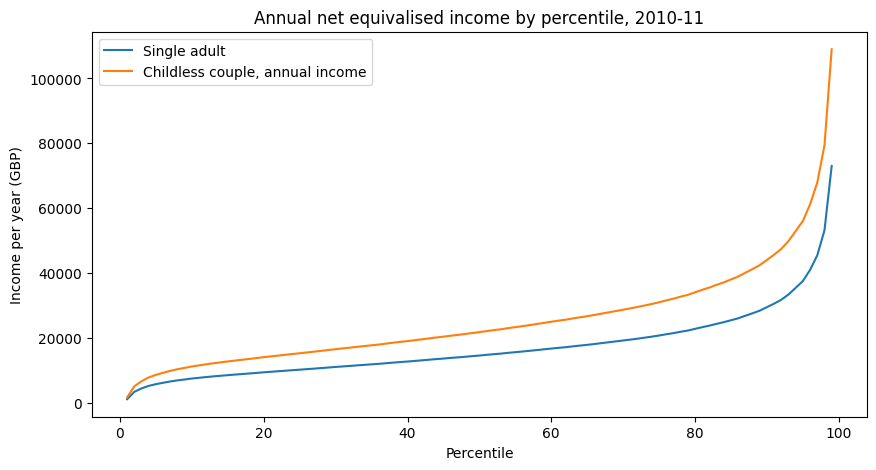

In [54]:
cols = ["Single adult", "Childless couple, annual income"]
clean = income[cols].apply(lambda col: pd.to_numeric(col.str.replace(",", ""), errors="coerce"))

print(clean.dtypes)
print("NaNs created:", clean.isna().sum().sum())
clean.plot()
plt.title("Annual net equivalised income by percentile, 2010-11")
plt.xlabel("Percentile")
plt.ylabel("Income per year (GBP)")
plt.show()

It is usually better to fix types **when reading the file**. `read_csv` has arguments for exactly this:

In [55]:
income2 = pd.read_csv("https://s3.eu-west-2.amazonaws.com/qm2/wk2/incomes.csv", index_col=0,
                      thousands=",")
income2.dtypes

,0
"Net equivalised household income in 2010-11, week",float64
"Childless couple, annual income",float64
"Couple, two children under 14",float64
"Couple, three children under 14",float64
Couple with one child under 14,float64
Couple with two children aged 15 to 18,float64
"Couple, two children under 14 plus dependent adult",float64
Single adult,float64
"Lone parent, one child under 14",float64
"Lone parent, two children under 14",float64


### Exercise: what is still wrong?

`thousands=","` fixed most columns, but not all of them.

1. Which columns are still text, and why? Look at their values.
2. Convert the three growth-rate columns (`"1979 to 1996-97"` etc.) to numbers. (Hint: `.str.rstrip("%")`, and remember to divide by 100 if you want proportions.)
3. The `ANNOTATIONS` column has one non-missing value. What is it, and why does it break the rule "one column = one variable"?

In [56]:
# Inspect the columns that are still text after thousands=","
text_columns = income2.select_dtypes(include=["object", "string"]).columns
print("Columns currently stored as text:", text_columns.tolist())
for column in text_columns:
    print("\n" + column)
    display(income2[column].dropna().head())

growth_columns = [
    "1979 to 1996-97",
    "1996-97 to 2009-10",
    "1996-97 to 2010-11"
]

# Convert only text columns, so rerunning does not divide by 100 twice
for column in growth_columns:
    if not pd.api.types.is_numeric_dtype(income2[column]):
        values = income2[column].str.rstrip("%")
        converted = pd.to_numeric(values, errors="coerce")
        newly_missing = values.notna() & converted.isna()
        assert not newly_missing.any(), "Unexpected non-numeric growth value"
        income2[column] = converted / 100

print("\nGrowth-rate dtypes after conversion:")
print(income2[growth_columns].dtypes)
display(income2[growth_columns].head())
print("1.90% is stored as the proportion 0.019.")
print("The percentage signs caused the three growth columns to be text.")


Columns currently stored as text: ['ANNOTATIONS', '1979 to 1996-97', '1996-97 to 2009-10', '1996-97 to 2010-11']

ANNOTATIONS


,ANNOTATIONS
Percentile Point,
16,Poverty line



1979 to 1996-97


,1979 to 1996-97
Percentile Point,
2,-0.20%
3,0.40%
4,0.50%
5,0.70%
6,0.70%



1996-97 to 2009-10


...


1996-97 to 2010-11


,1996-97 to 2010-11
Percentile Point,
2,-0.50%
3,0.10%
4,0.60%
5,0.90%
6,1.00%



Growth-rate dtypes after conversion:
1979 to 1996-97       float64
1996-97 to 2009-10    float64
1996-97 to 2010-11    float64
dtype: object


,1979 to 1996-97,1996-97 to 2009-10,1996-97 to 2010-11
Percentile Point,,,
1,NaN,NaN,NaN
2,-0.002,-0.013,-0.005
3,0.004,0.001,0.001
4,0.005,0.008,0.006
5,0.007,0.010,0.009


1.90% is stored as the proportion 0.019.
The percentage signs caused the three growth columns to be text.


In [57]:
income2.loc[
    income2["ANNOTATIONS"].notna(),
    ["ANNOTATIONS"]
]

,ANNOTATIONS
Percentile Point,
16,Poverty line


### 3.2 Filtering by value

A boolean condition gives a column of True/False values, one per row. Put it inside `[ ]` to keep only the rows where it is True:

In [58]:
clean["Childless couple, annual income"] > 50000

,"Childless couple, annual income"
Percentile Point,
1,False
2,False
3,False
4,False
5,False
...,...
95,True
96,True
97,True


In [59]:
clean[clean["Childless couple, annual income"] > 50000]

,Single adult,"Childless couple, annual income"
Percentile Point,,
94,35505.56,52993.38
95,37579.34,56088.56
96,41028.91,61237.18
97,45509.80,67925.07
98,53214.90,79425.23
99,73023.80,108990.74


Comparison operators: `==` (equal; a single `=` means assignment), `!=`, `<`, `<=`, `>`, `>=`. Combine conditions with `&` (and) and `|` (or), with each condition in brackets.

### Exercise: single adults

On a properly labelled graph, plot the incomes of single adults whose net equivalised income is at most £10,000 a year. What proportion of the population is this? Then compare single adults with childless couples at the 1st, 50th and 99th percentiles: what does it tell you about the equivalisation scale?

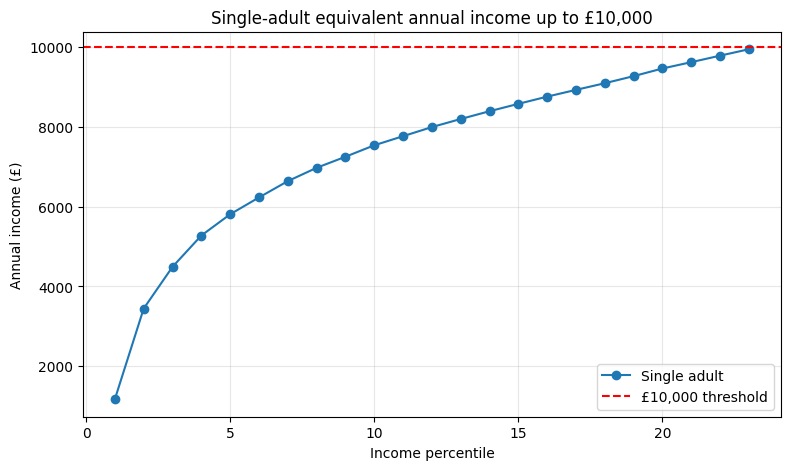

Highest percentile at or below £10,000: 23


,Single adult
Percentile Point,
23,9951.14
24,10117.29


Approximately 23% of the ranked equivalised-income distribution.
This is not a demographic estimate of how many people are single adults.


,Single adult,"Childless couple, annual income",Couple / single
Percentile Point,,,
1,1170.44,1746.92,1.49
50,14627.95,21832.75,1.49
99,73023.80,108990.74,1.49


The fixed couple/single ratio is about 1.49, reflecting shared household costs.


In [60]:
# Select single-adult equivalent annual incomes at most £10,000
low_income_single = income2.loc[
    income2["Single adult"] <= 10000, ["Single adult"]
]
low_income_single.plot(marker="o", legend=False, figsize=(9, 5))
plt.axhline(10000, color="red", linestyle="--", label="£10,000 threshold")
plt.title("Single-adult equivalent annual income up to £10,000")
plt.xlabel("Income percentile")
plt.ylabel("Annual income (£)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

highest_percentile = low_income_single.index.max()
print("Highest percentile at or below £10,000:", highest_percentile)
display(income2.loc[23:24, ["Single adult"]])
print("Approximately 23% of the ranked equivalised-income distribution.")
print("This is not a demographic estimate of how many people are single adults.")

comparison = income2.loc[[1, 50, 99], [
    "Single adult", "Childless couple, annual income"
]].copy()
comparison["Couple / single"] = (
    comparison["Childless couple, annual income"] / comparison["Single adult"]
)
display(comparison.round(2))
print("The fixed couple/single ratio is about 1.49, reflecting shared household costs.")


### 3.3 Categories and dates

Two more dtypes you will meet constantly:

- **category**: a variable that takes a small, fixed set of values (flag state, gear type, region). Storing it as `category` uses less memory, and an **ordered** category (like the debt buckets from section 1) sorts in its logical order, not alphabetically.
- **datetime**: text like `"2023-07"` means nothing to pandas until you convert it with `pd.to_datetime`. After conversion you can extract years and months, sort in time order and resample.

In [61]:
print(rr["debt_bucket"].dtype)
print(rr["debt_bucket"].cat.categories.tolist())

rr["Country"] = rr["Country"].astype("category")
rr.dtypes

category
['0-30%', '30-60%', '60-90%', '90%+']


,0
Country,category
Year,int64
debtgdp,float64
dRGDP,float64
debt_bucket,category


In [62]:
months = pd.Series(["Nov 2023", "Feb 2023", "Jan 2024"])
print(months.sort_values().tolist())        # sorted as text: alphabetical, not chronological

dates = pd.to_datetime(months, format="%b %Y")
print(dates.sort_values().dt.strftime("%b %Y").tolist())
print(dates.dt.year.tolist(), dates.dt.month_name().tolist())

try:
    pd.to_datetime(pd.Series(["03/04/2024", "13/04/2024"]), format="%m/%d/%Y")
except ValueError as err:
    print("ValueError:", str(err)[:80])

['Feb 2023', 'Jan 2024', 'Nov 2023']
['Feb 2023', 'Nov 2023', 'Jan 2024']
[2023, 2023, 2024] ['November', 'February', 'January']
ValueError: time data "13/04/2024" doesn't match format "%m/%d/%Y", at position 1. You might


The last line is the classic date trap: `03/04/2024` is 3 April in the UK and March 4 in the US. Always pass an explicit `format=`, so that pandas fails loudly rather than silently guessing.

## 4. Panel data: wide vs long

**Panel data** records the same units (countries, vessels, firms) repeatedly over time. The lecture showed World Bank GDP in two layouts:

- **wide**: one row per country, one column per year. Compact, and how most published tables look.
- **long**: one row per country × year. More repetition, but adding a variable means adding one column, and it is what `groupby`, plotting and regression expect.

Our API result is already long. `pivot` makes it wide, which reproduces the lecture's table:

In [63]:
gdp_wide = gdp.pivot(index="country", columns="year", values="gdp_bn")
gdp_wide[[2019, 2020, 2021]].round(1)

year,2019,2020,2021
country,,,
Angola,81.2,58.5,78.3
Brazil,1873.3,1476.1,1670.6
Colombia,323.0,270.3,318.5


`melt` goes the other way, from wide to long. `id_vars` stays fixed, and all the other columns are "melted" into two: one holding the old column names (`var_name`) and one holding the values (`value_name`).

In [64]:
gdp_long = gdp_wide.reset_index().melt(id_vars="country", var_name="year", value_name="gdp_bn")
print(gdp_wide.shape, "->", gdp_long.shape)
gdp_long.head()

(3, 25) -> (75, 3)


,country,year,gdp_bn
0,Angola,2000,9.129595
1,Brazil,2000,655.448232
2,Colombia,2000,99.875075
3,Angola,2001,8.936079
4,Brazil,2001,559.983635


### 4.1 Global Fishing Watch: fishing effort by flag state

[Global Fishing Watch](https://globalfishingwatch.org) uses the AIS signals that ships broadcast to estimate where and when vessels are fishing. The file below gives **apparent fishing hours** per month for the ten flag states with the most fishing effort, 2017-2024. Like many published datasets it comes in **wide** format: one row per flag and one column per month.

*Data: Global Fishing Watch, [fishing effort v3](https://globalfishingwatch.org/dataset-and-code-fishing-effort/), licensed CC BY-NC 4.0.*

In [65]:
fish_wide = pd.read_csv("https://storage.googleapis.com/qm2/2627/w02/fishing_hours_by_flag_wide.csv",
                        index_col="flag")
print(fish_wide.shape)
fish_wide.iloc[:, :6]

(10, 96)


,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06
flag,,,,,,
CHN,516065.0,491399.0,931656.0,1374245,262149,305613
TWN,181201.0,157107.0,164549.0,231917,227847,210907
KOR,90687.0,86070.0,104216.0,117044,162617,178586
ESP,152648.0,137025.0,177311.0,168193,219950,230783
ITA,135206.0,170771.0,205276.0,174239,273744,287198
RUS,135968.0,145381.0,174577.0,153922,150192,153760
USA,105330.0,119962.0,121349.0,123421,129441,149916
JPN,125162.0,104445.0,103993.0,105902,129725,130546
FRA,129467.0,118467.0,145698.0,136067,139850,141090


Ten rows and 96 columns. (Why are the first few columns shown as decimals and the rest as whole numbers? Look for `NaN`.) The column names are **values** (months), not variable names: that is the lecture's first cause of messiness. To plot a time series or compute annual totals, we want long format with one row per flag × month:

In [66]:
fish = fish_wide.reset_index().melt(id_vars="flag", var_name="month", value_name="fishing_hours")
fish["month"] = pd.to_datetime(fish["month"], format="%Y-%m")
fish["flag"] = fish["flag"].astype("category")
print(fish.dtypes)
fish.head()

flag                   category
month            datetime64[ns]
fishing_hours           float64
dtype: object


,flag,month,fishing_hours
0,CHN,2017-01-01,516065.0
1,TWN,2017-01-01,181201.0
2,KOR,2017-01-01,90687.0
3,ESP,2017-01-01,152648.0
4,ITA,2017-01-01,135206.0


To plot, pivot back so that time is the index and each flag is a column (one line per column). A common workflow is **long for analysis, wide for plotting**:

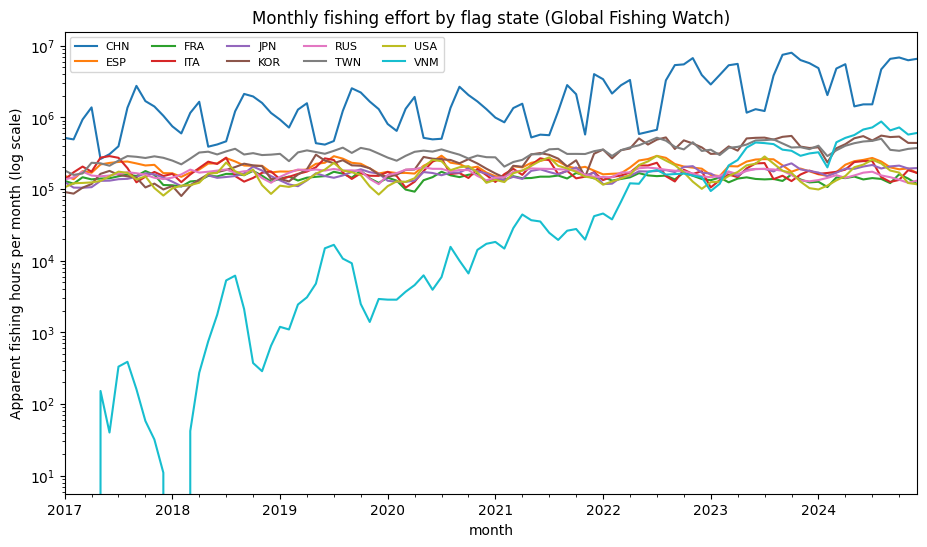

In [67]:
fish.pivot(index="month", columns="flag", values="fishing_hours").plot(logy=True, figsize=(11, 6))
plt.ylabel("Apparent fishing hours per month (log scale)")
plt.title("Monthly fishing effort by flag state (Global Fishing Watch)")
plt.legend(ncol=5, fontsize=8)
plt.show()

Now that the data is long and `month` is a real datetime, questions become one-liners. Seasonality in China's fleet:

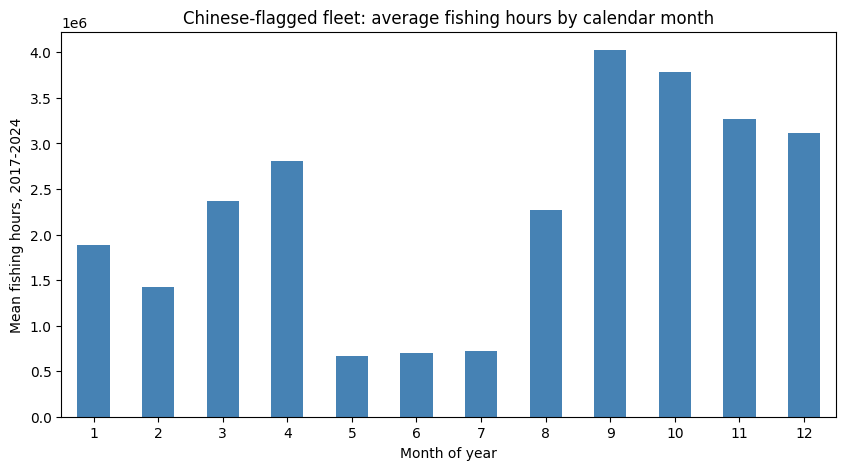

In [68]:
chn = fish[fish["flag"] == "CHN"]
chn.groupby(chn["month"].dt.month)["fishing_hours"].mean().plot(kind="bar", color="steelblue")
plt.xlabel("Month of year")
plt.ylabel("Mean fishing hours, 2017-2024")
plt.title("Chinese-flagged fleet: average fishing hours by calendar month")
plt.xticks(rotation=0)
plt.show()

### Exercise: seasonality

Is the dip in the middle of the year a data problem or something real? (Hint: search for *China summer fishing moratorium*.) Make the same plot for a European flag (for example `ESP` or `FRA`). Is there a similar pattern?

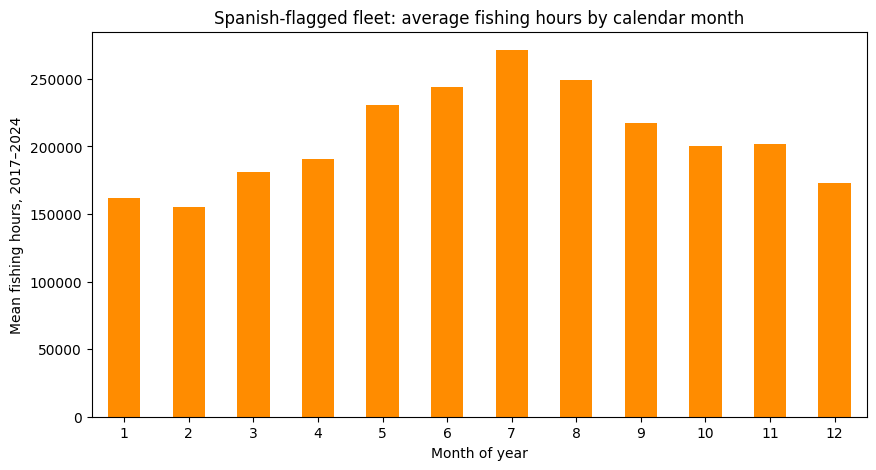

In [69]:
esp = fish[fish["flag"] == "ESP"]

esp.groupby(
    esp["month"].dt.month
)["fishing_hours"].mean().plot(
    kind="bar",
    color="darkorange"
)

plt.xlabel("Month of year")
plt.ylabel("Mean fishing hours, 2017–2024")
plt.title("Spanish-flagged fleet: average fishing hours by calendar month")
plt.xticks(rotation=0)
plt.show()

### Exercise: spot the problem

A blog post writes:

> *"Fishing by the world's top ten fleets nearly **tripled** between 2017 and 2024. Vietnam's fishing effort grew more than a thousand-fold. The oceans are being emptied faster than ever."*

1. Reproduce the numbers: compute annual totals per flag (`fish["month"].dt.year` and `groupby`), then a bar chart of the ten-flag total by year.
2. Which flags drive the jump, and in which years? Does the jump look like a gradual trend or a step change?
3. These are hours *detected through AIS*. List at least two reasons why detected fishing could rise without any real change in fishing (think about which vessels carry AIS transponders, and about the satellites that receive their signals).
4. `fish_wide` has some missing values. Which flag and months? What does `.sum()` do with `NaN`, and how could that inflate a growth rate?
5. The ten flags were chosen *because* they have the most fishing hours over 2017-2024. How does that selection affect the conclusion?

year,2017,2018,2019,2020,2021,2022,2023,2024
flag,,,,,,,,
CHN,12.52,13.43,14.75,15.22,17.09,38.21,52.51,52.44
ESP,2.39,2.44,2.54,2.44,2.48,2.58,2.50,2.46
FRA,1.72,1.72,1.78,1.67,1.75,1.78,1.65,1.62
ITA,2.31,2.14,2.12,2.06,2.17,2.06,1.95,2.17
JPN,1.59,1.78,1.80,1.88,1.96,2.00,2.17,2.29
KOR,1.51,1.94,2.42,2.64,2.82,4.92,5.23,5.44
RUS,1.85,1.99,2.04,2.11,2.08,2.07,1.98,1.76
TWN,2.82,3.61,3.93,3.64,3.56,4.76,4.83,4.73
USA,1.56,1.73,1.75,2.09,2.21,2.15,2.10,1.98


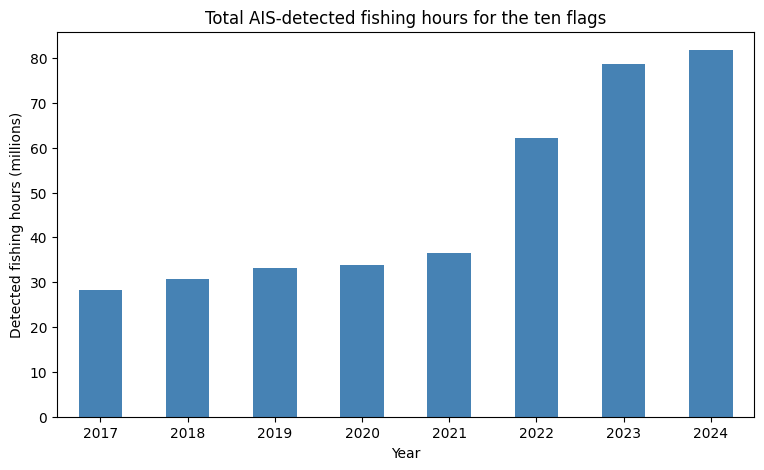

Total increase factor: 2.89 times
Vietnam increase factor: 5859.9 times


,2017 hours,2024 hours,increase,growth factor,share of total increase (%)
flag,,,,,
CHN,12523458.0,52444468.0,39921010.0,4.19,74.62
VNM,1174.0,6879526.0,6878352.0,5859.90,12.86
KOR,1513220.0,5436460.0,3923240.0,3.59,7.33
TWN,2818622.0,4727097.0,1908475.0,1.68,3.57
JPN,1592347.0,2293628.0,701281.0,1.44,1.31
USA,1561435.0,1982138.0,420703.0,1.27,0.79
ESP,2388327.0,2460161.0,71834.0,1.03,0.13
RUS,1852637.0,1759197.0,-93440.0,0.95,-0.17
FRA,1719214.0,1620893.0,-98321.0,0.94,-0.18


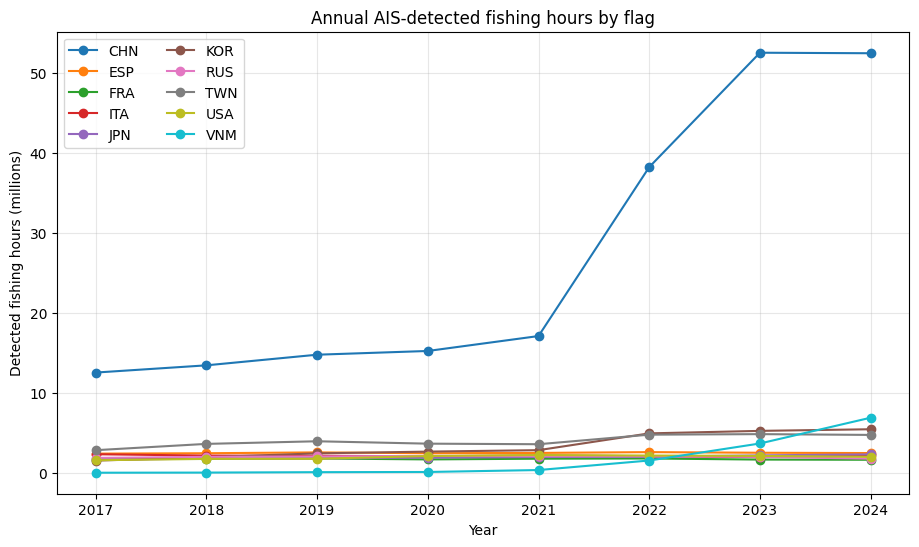

Absolute annual increases in detected hours:


year,2022,2023,2024
flag,,,
CHN,21122319.0,14299619.0,-65114.0
KOR,2099351.0,312489.0,203350.0
TWN,1194210.0,67906.0,-99143.0
VNM,1191421.0,2128918.0,3222756.0
ESP,101015.0,-79936.0,-37507.0
JPN,35496.0,173367.0,122495.0
FRA,28637.0,-137235.0,-24162.0
RUS,-6541.0,-99504.0,-215946.0
USA,-60088.0,-46951.0,-117825.0


Year-on-year change of the ten-flag total (%):


,0
year,
2017,NaN
2018,8.9
2019,7.9
2020,1.9
2021,7.8
2022,70.2
2023,26.6
2024,4.1


Missing flag-months:


,flag,month
9,VNM,2017-01-01
19,VNM,2017-02-01
29,VNM,2017-03-01


Vietnam annual totals and observed-month counts:


,sum,count
year,,
2017,1174.0,9
2018,17716.0,12
2019,70740.0,12
2020,93527.0,12
2021,336431.0,12
2022,1527852.0,12
2023,3656770.0,12
2024,6879526.0,12


VNM 2017 total when 12 observed months are required: nan
Default sum skips NaN; Vietnam's 2017 denominator has only nine observed months.
Read the written answers below for AIS coverage, selection bias and interpretation.


In [70]:
# Extract year
fish["year"] = fish["month"].dt.year

# Annual total for each flag
annual_by_flag = (
    fish.groupby(
        ["flag", "year"],
        observed=True
    )["fishing_hours"]
    .sum()
    .unstack("year")
)

display((annual_by_flag / 1_000_000).round(2))


# Total across all ten flags
annual_total = annual_by_flag.sum(axis=0)

(annual_total / 1_000_000).plot(
    kind="bar",
    color="steelblue",
    figsize=(9, 5)
)

plt.xlabel("Year")
plt.ylabel("Detected fishing hours (millions)")
plt.title("Total AIS-detected fishing hours for the ten flags")
plt.xticks(rotation=0)
plt.show()


total_factor = annual_total.loc[2024] / annual_total.loc[2017]
vietnam_factor = (
    annual_by_flag.loc["VNM", 2024]
    / annual_by_flag.loc["VNM", 2017]
)

print(f"Total increase factor: {total_factor:.2f} times")
print(f"Vietnam increase factor: {vietnam_factor:.1f} times")

flag_change = pd.DataFrame({
    "2017 hours": annual_by_flag[2017],
    "2024 hours": annual_by_flag[2024]
})

flag_change["increase"] = (
    flag_change["2024 hours"]
    - flag_change["2017 hours"]
)

flag_change["growth factor"] = (
    flag_change["2024 hours"]
    / flag_change["2017 hours"]
)

flag_change["share of total increase (%)"] = (
    flag_change["increase"]
    / (annual_total[2024] - annual_total[2017])
    * 100
)

display(
    flag_change.sort_values(
        "increase",
        ascending=False
    ).round(2)
)
(annual_by_flag.T / 1_000_000).plot(
    marker="o",
    figsize=(11, 6)
)

plt.xlabel("Year")
plt.ylabel("Detected fishing hours (millions)")
plt.title("Annual AIS-detected fishing hours by flag")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.show()

# Identify the years and flag states behind the jump
annual_increases = annual_by_flag.diff(axis=1)
print("Absolute annual increases in detected hours:")
display(annual_increases[[2022, 2023, 2024]].sort_values(2022, ascending=False))
print("Year-on-year change of the ten-flag total (%):")
display((annual_total.pct_change() * 100).round(1))

# Missing observations: do not silently treat incomplete years as full years
missing_fishing = fish.loc[fish["fishing_hours"].isna(), ["flag", "month"]]
print("Missing flag-months:")
display(missing_fishing)
print("Vietnam annual totals and observed-month counts:")
display(fish.loc[fish["flag"] == "VNM"].groupby("year")["fishing_hours"].agg(["sum", "count"]))

complete_annual = (
    fish.groupby(["flag", "year"], observed=True)["fishing_hours"]
    .sum(min_count=12).unstack("year")
)
print("VNM 2017 total when 12 observed months are required:", complete_annual.loc["VNM", 2017])
print("Default sum skips NaN; Vietnam's 2017 denominator has only nine observed months.")
print("Read the written answers below for AIS coverage, selection bias and interpretation.")

### Tidy data: recap

The lecture's rules, which you have now applied to real data:

1. Each **column** is one variable (not a value like `2019-03`, and not a mix like `"01Why Did I..."`).
2. Each **row** is one observation (one country-year, one flag-month).
3. Values are **numeric** where possible, with the right dtype (no `"14,627.95"`, no `"1:51"`).
4. Metadata (footnotes, annotations like "Poverty line") does not belong inside a data column.

**Next:** the reading-week notebook (*Merging and Joining*) shows how to combine two tidy tables that share a key, for example World Bank indicators and GFW effort by country. Week 3 extends this to joining on *location*.

# Written answers and interpretation

## 1. Spot the spreadsheet error

The three choices are (1) excluding the first five alphabetically sorted countries, (2) selectively excluding early country-years, and (3) giving each country equal weight after first averaging its country-years. The omitted countries are Australia, Austria, Belgium, Canada and Denmark. The early-year rule excludes Australia and Canada before 1951 and New Zealand before 1950; in the already restricted published sample, Australia and Canada are absent, so only the New Zealand exclusions take additional effect.

Undoing each choice independently relative to the published baseline gives approximately -0.02% (baseline), 0.30% (restore omitted countries), 1.43% (restore early years), and 1.69% (use equal country-year weights). Undoing all three gives 2.17%. Equal-country weighting has the largest individual effect in this comparison. These changes interact and should not be added together.

New Zealand contributes one observation with growth -7.635%, yet receives the same 1/7 country weight as the UK and Greece, each with 19 observations. It therefore pulls the equal-country mean down disproportionately relative to its observation count. Equal-country weighting can be defensible when the estimand is the average country experience, but its sensitivity to short histories must be reported. Selective year exclusions need a consistent, transparent substantive reason. Accidentally omitting countries is an error.

**Reverse causality (two sentences):** Slow growth can reduce tax revenue and increase government borrowing, raising public debt. It can also lower the GDP denominator, so a high debt/GDP ratio can be a consequence of weak growth rather than evidence that debt caused it.

## 2. Mean vs median

The mean of the 99 weekly-income thresholds is about £490.04, above the median of £418.73, because the upper tail pulls the mean upwards. The median corresponds to the 50th-percentile equivalised income: approximately half of the ranked population is below it and half above.

The rows are percentile thresholds, not individual households or within-percentile group means. Their arithmetic mean is only a summary of those 99 thresholds, not the exact population mean household income; in particular, it does not describe the income distribution above the 99th-percentile threshold.

## 3. Another World Bank indicator and data vintage

The alternative indicator is total fisheries production (ER.FSH.PROD.MT) for Angola, Brazil and Colombia, 2000-2024. The missing-value table and counts in the code are the check on the current API response. On the checked download, all three series contain 25 non-missing annual observations. Missing values could arise from reporting delays, incomplete statistical coverage, irregular surveys, or changes in definitions. NaN means unavailable, not zero production.

Angola's 2019 GDP should be read from the live API output above. A different figure from an older lecture slide can reflect revisions to national accounts or other source estimates. Keep the download date as the data vintage.

## 4. Netflix Views

Views are approximately Hours Viewed divided by runtime in hours. Small differences from the displayed Views column are expected because published viewing figures are rounded. Holding hours viewed fixed, shorter titles obtain more viewing equivalents; this is not a count of unique viewers or evidence that shorter titles necessarily attract more people.

## 5. Wikipedia EEZ table

France comes first in this particular table, at approximately 11.69 million km². This is surprising if one thinks only of European mainland France. The country total includes maritime zones associated with overseas territories, including French Polynesia and New Caledonia. Small, widely dispersed islands can generate extensive EEZs. This ranking is specific to the source table and its geographic definitions.

## 6. What is still wrong?

After reading thousands separators correctly, ANNOTATIONS and the three growth-rate columns remain text. The growth-rate values contain percent signs, such as "1.90%". Removing the sign and dividing by 100 gives the proportion 0.019. The conversion checks the dtype before changing a column, so it can be rerun without dividing an already converted value again.

The only non-missing annotation is "Poverty line" at percentile 16. It is a free-text note about a row rather than a consistently defined measured variable. It is better treated as metadata, or replaced with an explicitly defined indicator. Text is a valid dtype for genuine categories; the problem here is the meaning of the note.

## 7. Single adults

The £10,000 threshold lies between percentile 23 (£9,951.14) and percentile 24 (£10,117.29), so approximately 23% of the ranked equivalised-income distribution is below it. Dividing the number of qualifying rows by 99 would be incorrect. These are equivalised-income percentiles, not a demographic estimate of the fraction of all people who are single adults earning under £10,000.

At percentiles 1, 50 and 99, the couple/single income ratio is consistently about 1.49 (equivalently, the single-adult amount is 0.67 of the couple amount). The scale assumes a couple needs more total income than one adult for an equivalent living standard, but less than double, reflecting shared housing, heating and other costs. These columns apply a fixed scale rather than independently estimating an earnings effect of coupling.

## 8. Seasonality

China's pronounced May-July dip is consistent with a real reduction in activity during its annual summer fishing moratorium. Global Fishing Watch independently documents this seasonal pattern. Exact closure dates and rules differ by area and gear. The flag-based dataset also includes vessels outside domestic waters, so activity does not fall to zero.

Spain does not show the same mid-year collapse; its mean detected hours peak around July. This supports a regulation-related interpretation of the Chinese dip, although a plot alone cannot exclude every measurement effect.

## 9. Spot the problem

The ten-flag total rises from 28,280,798 hours in 2017 to 81,776,299 in 2024: 2.89 times the initial level, or about 189% growth. Vietnam rises from 1,174 to 6,879,526 recorded hours, approximately 5,860 times the initial level. The arithmetic is reproducible, but the interpretation requires caution.

China accounts for about 74.6% of the absolute increase, Vietnam 12.9%, Korea 7.3% and Taiwan 3.6%. The total jumps about 70% in 2022 and 27% in 2023, predominantly through China, rather than following a smooth global trend.

Detected hours may rise without a real increase in fishing because more vessels install or activate AIS, because satellites or shore-based receivers capture more signals, or because vessel identification and classification improve. These are possible measurement mechanisms, not proof that a particular mechanism explains every change in this table.

Vietnam is missing January-March 2017. Default sum skips NaN and therefore returns the nine-month subtotal as if it were an annual total. Comparing this incomplete, very small baseline with a complete later year can inflate the ratio. Requiring 12 observations with sum(min_count=12) leaves the incomplete annual figure as NaN; missing months should not be filled with invented values.

The flags were selected after observing total recorded hours across 2017-2024. This is not a representative sample of all fleets and may favour fleets with large later recorded activity or improving AIS visibility. Consequently, this selected total cannot establish a global growth rate. Apparent fishing hours also do not directly measure catch tonnage or fish-stock depletion, so they cannot establish that oceans are being emptied faster.

### Sources for interpretation

- [Global Fishing Watch: seasonal patterns and the Chinese moratorium](https://globalfishingwatch.org/data/half-ocean-updating-global-footprint-fisheries/)
- [Global Fishing Watch: apparent fishing effort, methods and limitations](https://globalfishingwatch.org/dataset-and-code-fishing-effort/)
- [World Bank: why some data are unavailable](https://datahelpdesk.worldbank.org/knowledgebase/articles/191133-why-are-some-data-not-available)
- [Wikipedia EEZ table used in the exercise](https://en.wikipedia.org/wiki/Exclusive_economic_zone)


# Assessed Question

Data: [monthly fishing hours by flag](https://oballinger.github.io/BASC0005/data/assessed/w02_fishing_hours_by_flag_wide.csv).

The file may contain incorrect values or labels. Check flags, numeric types, duplicate flag-months, negative values and completeness before comparing years.

**How many of the ten flag states recorded MORE total fishing hours in 2021 than in 2020?**

Use a strict greater-than comparison, so equal totals do not count. The answer produced by the code below is **8**. Keep this answer for the Moodle Problem Set Answers quiz in December.


In [71]:
# Read the ASSESSED data separately from the workshop example
assessed_url = "https://oballinger.github.io/BASC0005/data/assessed/w02_fishing_hours_by_flag_wide.csv"
assessed_wide = pd.read_csv(assessed_url, thousands=",")
assessed_wide.columns = assessed_wide.columns.str.strip()
assessed_wide["flag"] = assessed_wide["flag"].str.strip().str.upper()
assert assessed_wide["flag"].nunique() == 10
assert not assessed_wide["flag"].duplicated().any()

assessed = assessed_wide.melt(
    id_vars="flag", var_name="month", value_name="fishing_hours"
)
assessed["month"] = pd.to_datetime(assessed["month"], format="%Y-%m")
assessed["fishing_hours"] = pd.to_numeric(assessed["fishing_hours"], errors="raise")
assert not assessed["fishing_hours"].lt(0).any()
assert not assessed.duplicated(["flag", "month"]).any()
assessed["year"] = assessed["month"].dt.year

selected = assessed[assessed["year"].isin([2020, 2021])]
counts = selected.groupby(["flag", "year"])["fishing_hours"].count()
assert len(counts) == 20 and counts.eq(12).all()

assessed_annual = (
    selected.groupby(["flag", "year"])["fishing_hours"]
    .sum(min_count=12).unstack("year")
)
assessed_annual["more_in_2021"] = assessed_annual[2021] > assessed_annual[2020]
display(assessed_annual)
assessed_answer = int(assessed_annual["more_in_2021"].sum())
print("Answer:", assessed_answer)
print("KOR uses thousands separators. Missing VNM months are in 2017, outside this comparison.")

year,2020,2021,more_in_2021
flag,,,
CHN,15222077.0,17087644.0,True
ESP,2439013.0,2476589.0,True
FRA,1665858.0,1753653.0,True
ITA,2057772.0,2170930.0,True
JPN,1881217.0,1962270.0,True
KOR,2641090.0,2821270.0,True
RUS,2105435.0,2081188.0,False
TWN,3635081.0,3564124.0,False
USA,2088425.0,2207002.0,True


Answer: 8
KOR uses thousands separators. Missing VNM months are in 2017, outside this comparison.
